# Credit Card Customer Segmentation - Unsupervised Learning

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from IPython.display import Markdown, display

## Step 1 - Dataset Loading & Exploratory Data Analysis
### 1.1 Load & inspect

In [4]:
df = pd.read_csv("../dataset/CC GENERAL.csv")
print('Shape:', df.shape)
df.head()

Shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [6]:
df = df.drop(columns='CUST_ID')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 17 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   BALANCE                           8950 non-null   float64
 1   BALANCE_FREQUENCY                 8950 non-null   float64
 2   PURCHASES                         8950 non-null   float64
 3   ONEOFF_PURCHASES                  8950 non-null   float64
 4   INSTALLMENTS_PURCHASES            8950 non-null   float64
 5   CASH_ADVANCE                      8950 non-null   float64
 6   PURCHASES_FREQUENCY               8950 non-null   float64
 7   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 8   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 9   CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 10  CASH_ADVANCE_TRX                  8950 non-null   int64  
 11  PURCHASES_TRX                     8950 non-null   int64  
 12  CREDIT_LIMIT     

In [14]:
imputed = {c: int(df[c].isnull().sum()) for c in ['CREDIT_LIMIT', 'MINIMUM_PAYMENTS']}
for c in imputed:
    df[c] = df[c].fillna(df[c].median)

print('Values imputed with column median')

Values imputed with column median


### 1.2 Univariate analysis

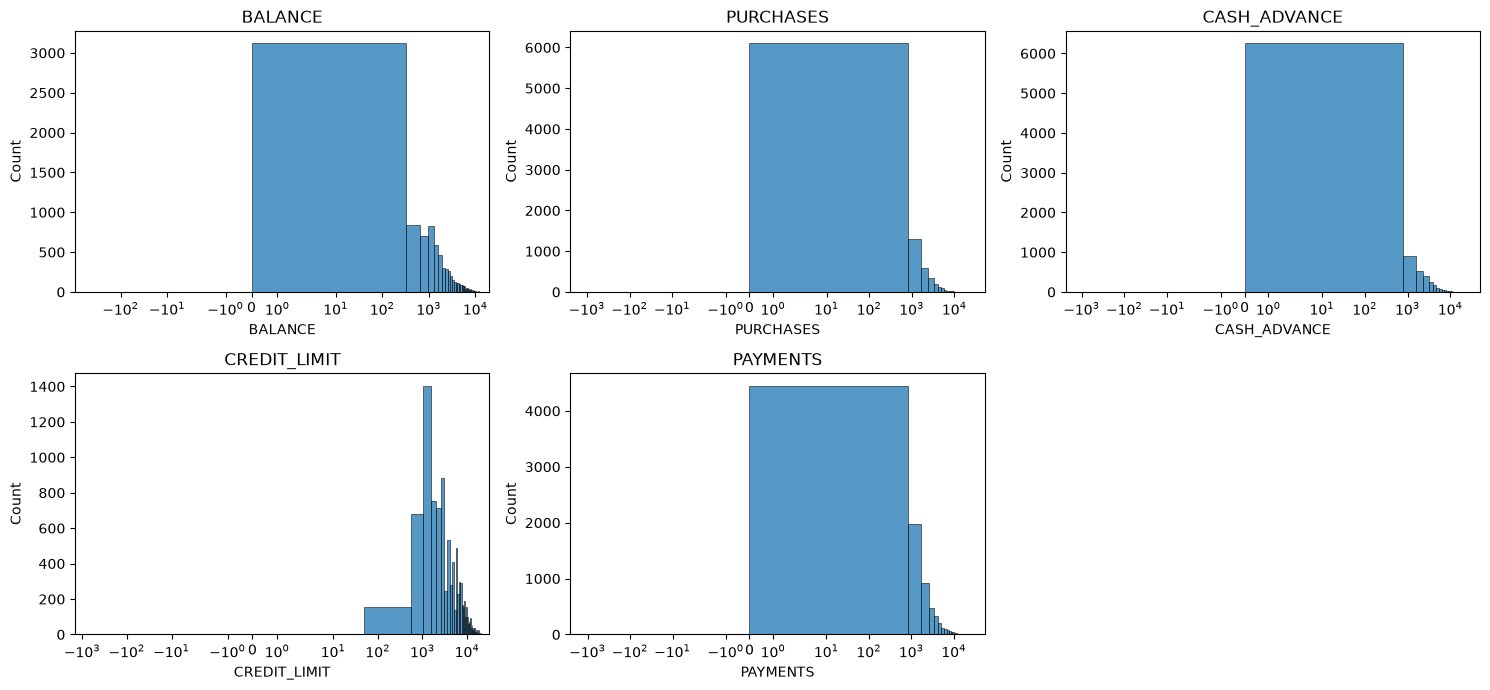

In [69]:

cols = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS']

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, c in zip(ax.ravel(), cols):
    sns.histplot(df[c], bins=60, ax=a)
    a.set_xscale('symlog')
    a.set_title(f'{c}')
    
ax.ravel()[-1].axis('off')
plt.tight_layout()
plt.savefig("../images/01.feature_distributions.png")
plt.show()

- The histograms show how customer values are distributed across the selected features. A right-skewed feature has many customers with lower values and a smaller number with very high values. This helps identify features that may need scaling or outlier handling before clustering.


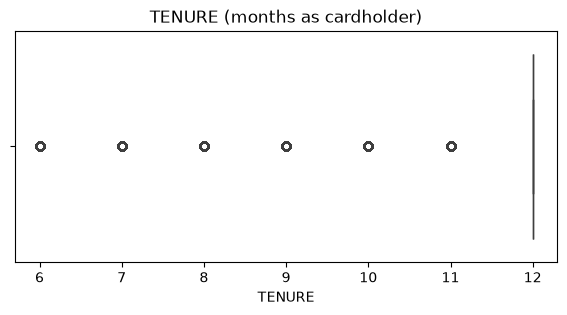

Tenure value counts:
 {6: 204, 7: 190, 8: 196, 9: 175, 10: 236, 11: 365, 12: 7584}


<Figure size 640x480 with 0 Axes>

In [ ]:

plt.figure(figsize=(7, 3))
sns.boxplot(x=df['TENURE'])
plt.title('TENURE (months as cardholder)')
plt.show()
print('Tenure value counts:\n', df['TENURE'].value_counts().sort_index().to_dict())

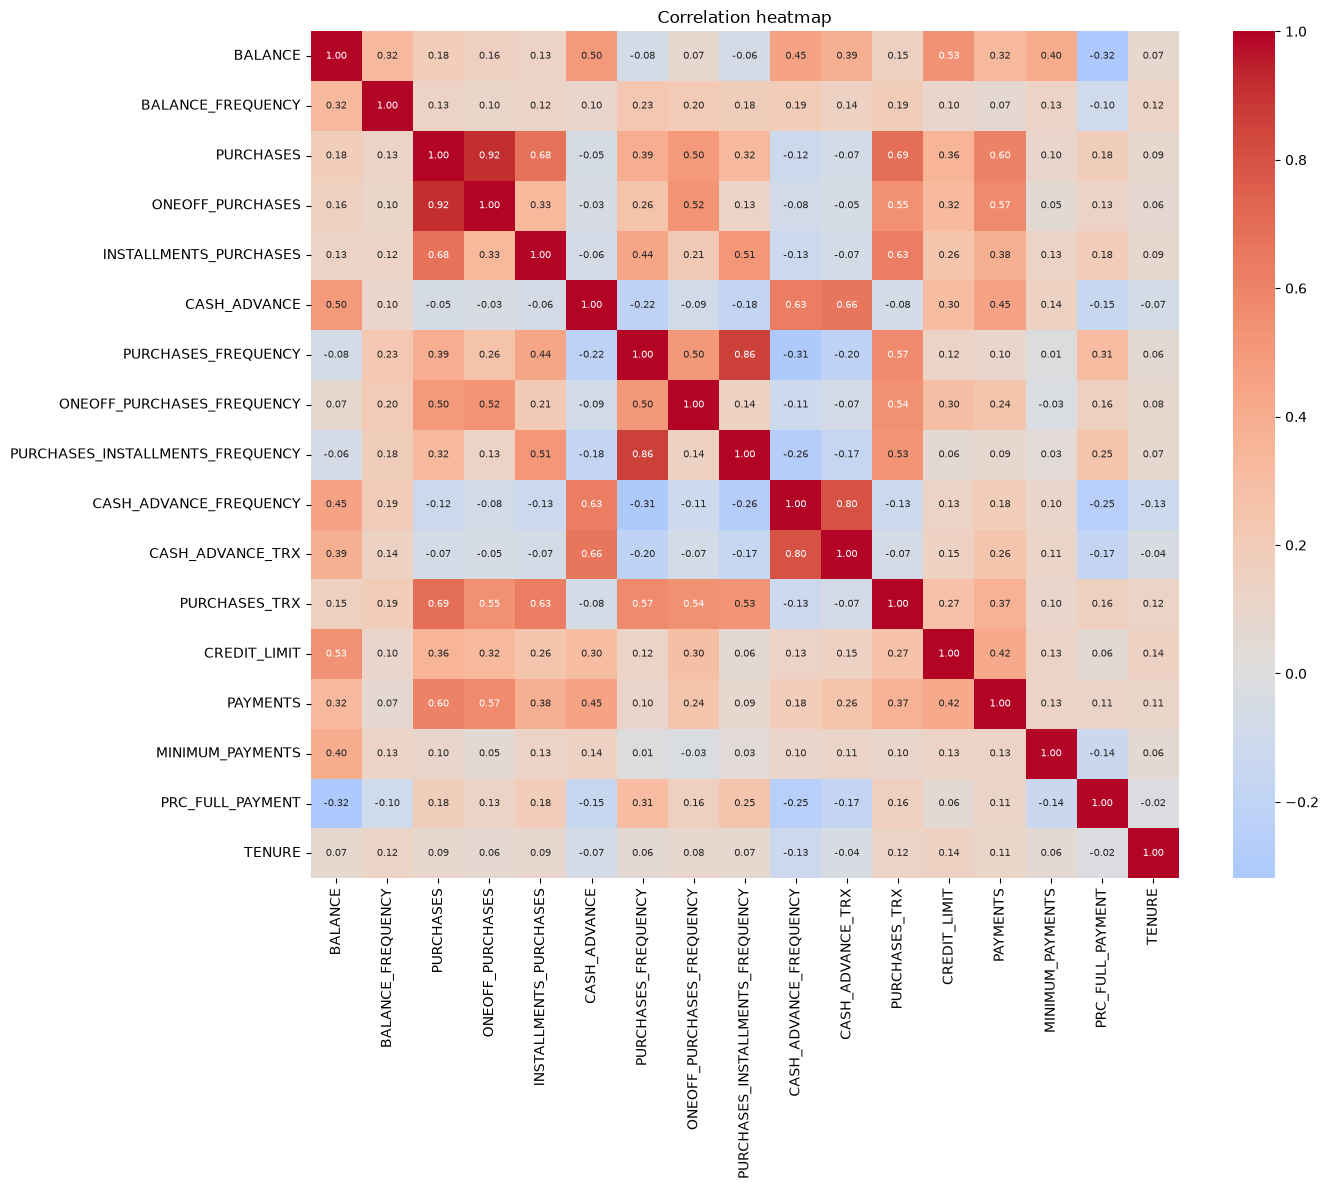

In [71]:
corr = df.corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Correlation heatmap')
plt.savefig("../images/02.feature_correlation_heatmap.png")
plt.show()

- The heatmap shows how strongly pairs of features vary together. Strong correlations indicate features that may carry similar information, while weak correlations suggest they describe different aspects of customer behavior. Correlation does not imply causation.


In [20]:
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
pairs = pairs[pairs.abs() > 0.7].sort_values(ascending=False)
print('Highly correlated pairs (|r| > 0.7):')
display(pairs.round(2).to_frame('r'))

Highly correlated pairs (|r| > 0.7):


,,r
PURCHASES,ONEOFF_PURCHASES,0.92
PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,0.86
CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,0.80


### 1.3 Customer-level analysis

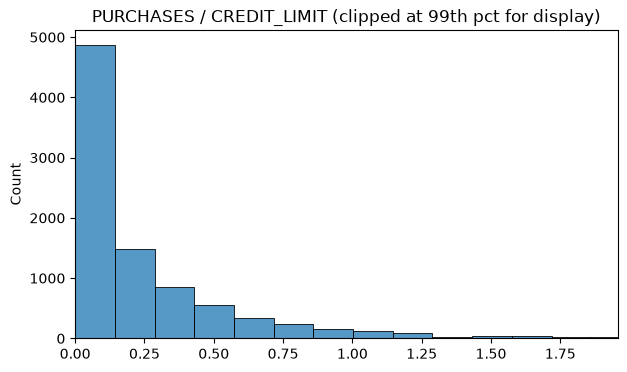

In [22]:
util = df['PURCHASES'] / df['CREDIT_LIMIT']
plt.figure(figsize=(7, 4))
sns.histplot(util, bins=60)
plt.xlim(0, util.quantile(.99))
plt.title('PURCHASES / CREDIT_LIMIT (clipped at 99th pct for display)')
plt.show()

In [23]:
top10 = df.nlargest(10, 'CASH_ADVANCE')[['CASH_ADVANCE', 'PURCHASES', 'BALANCE', 'CREDIT_LIMIT']]
display(top10.round(1))
print(f"Median PURCHASES overall: {df.PURCHASES.median():.0f} | top-10 cash-advance median PURCHASES: {top10.PURCHASES.median():.0f}")
print(f"Customers with PURCHASES == 0: {(df.PURCHASES == 0).mean() * 100:.2f}%")
s = df['PURCHASES'].sort_values(ascending=False).cumsum() / df['PURCHASES'].sum()
pareto = (s < 0.8).sum() + 1
print(f"Pareto: {pareto} customers = {pareto / len(df) * 100:.1f}% of cardholders generate 80% of total PURCHASES")

,CASH_ADVANCE,PURCHASES,BALANCE,CREDIT_LIMIT
2159,47137.2,431.9,10905.1,19600.0
1059,29282.1,3719.0,8823.3,15500.0
71,27296.5,4523.3,2990.4,7000.0
7254,26268.7,1750.7,4530.2,8500.0
7645,26194.0,0.0,7081.2,9000.0
2454,23130.8,0.0,10915.6,15000.0
883,22665.8,0.0,14581.5,18500.0
6371,21943.8,0.0,4529.9,13000.0
3806,20712.7,4995.8,14100.3,16500.0
6455,20277.3,1490.8,9111.0,11000.0


Median PURCHASES overall: 361 | top-10 cash-advance median PURCHASES: 961
Customers with PURCHASES == 0: 22.84%
Pareto: 2346 customers = 26.2% of cardholders generate 80% of total PURCHASES


## Step 2 - Feature Engineering & Preprocessing
### 2.1 Behavioural features

In [24]:
RAW_COLS = list(df.columns)
def add_features(d):
    f = d[RAW_COLS].copy()
    t = f['TENURE'].clip(lower=1)
    f['Monthly_Avg_Purchase'] = f['PURCHASES'] / t
    f['Monthly_Avg_Cash_Advance'] = f['CASH_ADVANCE'] / t
    f['Limit_Usage'] = np.where(f['CREDIT_LIMIT'] > 0, f['BALANCE'] / f['CREDIT_LIMIT'].where(f['CREDIT_LIMIT'] > 0, 1), 0)
    f['Payment_to_Minpayment_Ratio'] = f['PAYMENTS'] / (f['MINIMUM_PAYMENTS'] + 1)
    return f

fe = add_features(df)
NEW = ['Monthly_Avg_Purchase', 'Monthly_Avg_Cash_Advance', 'Limit_Usage', 'Payment_to_Minpayment_Ratio']
print(fe.shape)
display(fe[NEW].describe().round(2))
print('Skewness:\n', fe[NEW].skew().round(2))

(8950, 21)


,Monthly_Avg_Purchase,Monthly_Avg_Cash_Advance,Limit_Usage,Payment_to_Minpayment_Ratio
count,8950.00,8950.00,8950.00,8950.00
mean,86.18,88.98,0.39,6.39
std,180.51,193.14,0.39,32.00
min,0.00,0.00,0.00,0.00
25%,3.40,0.00,0.04,0.91
50%,31.94,0.00,0.30,2.02
75%,97.23,99.09,0.72,6.01
max,4086.63,3928.10,15.91,1863.85


Skewness:
 Monthly_Avg_Purchase            8.00
Monthly_Avg_Cash_Advance        4.94
Limit_Usage                     7.42
Payment_to_Minpayment_Ratio    36.90
dtype: float64


### 2.2 Outliers (IQR cap at Q3 + 3×IQR - winsorisation, no rows dropped)

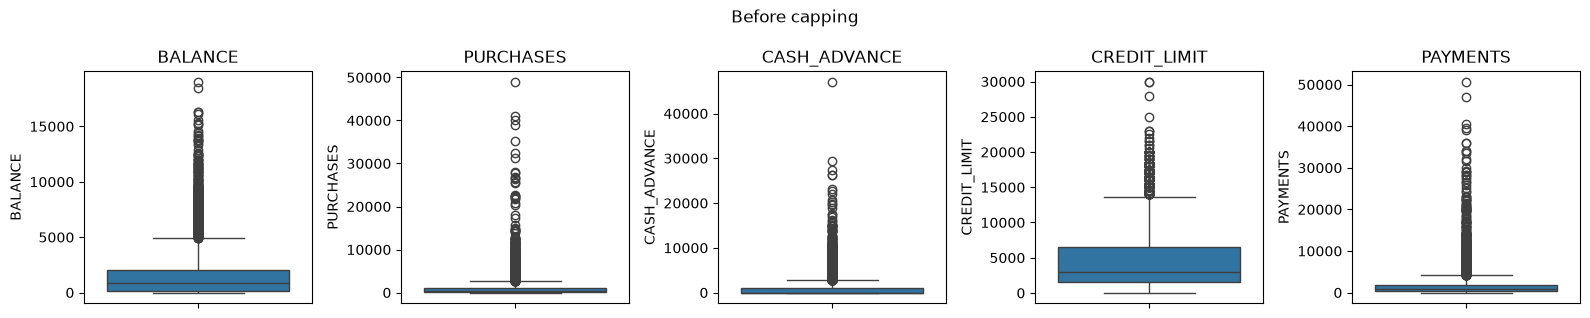

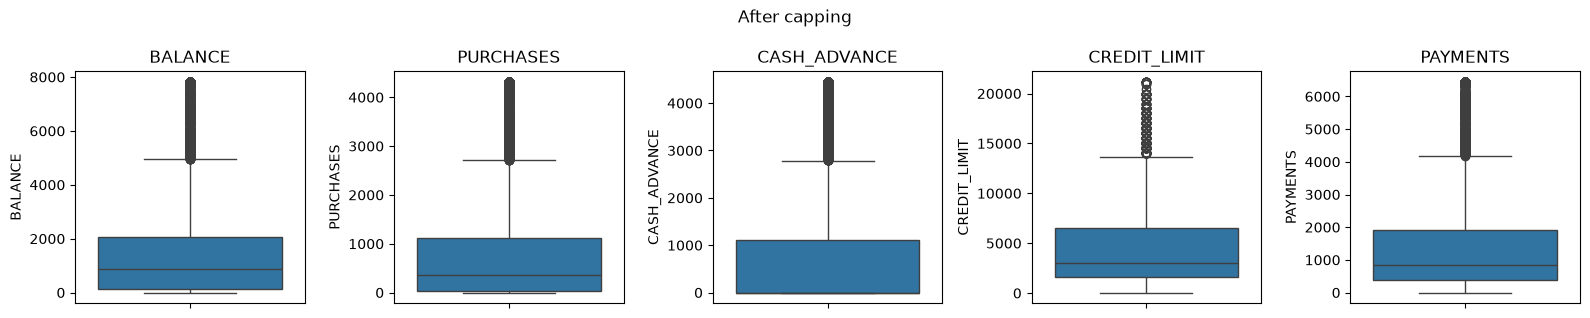

In [26]:
MONEY = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS']
CAP_COLS = MONEY + ['CASH_ADVANCE_TRX', 'PURCHASES_TRX'] + NEW

def box(data, title):
    fig, ax = plt.subplots(1, 5, figsize=(16, 3.2))
    for a, c in zip(ax, cols): 
        sns.boxplot(y=data[c], ax=a)
        a.set_title(c)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    
box(fe, 'Before capping')
caps = {}

for c in CAP_COLS:
    q1, q3 = fe[c].quantile([.25, .75])
    iqr = q3 - q1
    if iqr > 0: 
        caps[c] = q3 + 3 * iqr
    
fe_cap = fe.copy()
n_capped = {}

for c, u in caps.items(): 
    n_capped[c] = int((fe[c] > u).sum())
    fe_cap[c] = fe[c].clip(upper=u)
box(fe_cap, 'After capping')

### 2.3 Transform skewed features (log1p)

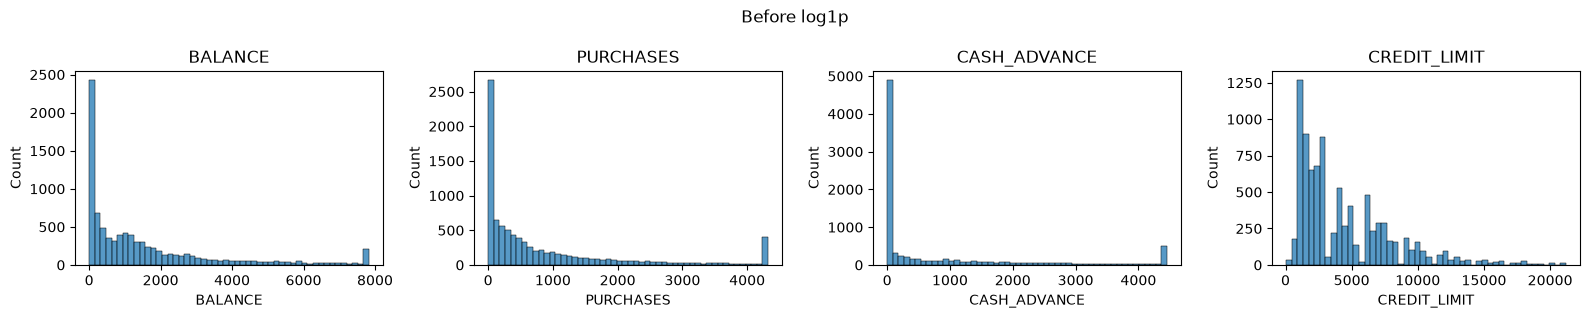

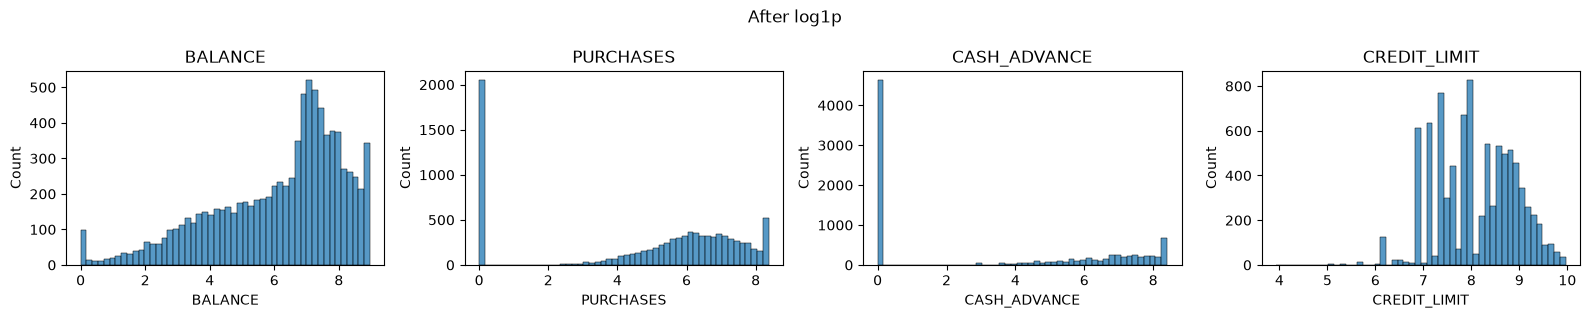

Skew before -> after:
               before  after
BALANCE         1.73  -0.88
PURCHASES       1.79  -0.81
CASH_ADVANCE    1.69   0.24
CREDIT_LIMIT    1.45  -0.10
PAYMENTS        1.73  -1.98


In [27]:
LOG_COLS = CAP_COLS
def hist4(data, title):
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
    
    for a, c in zip(ax, ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT']): 
        sns.histplot(data[c], bins=50, ax=a)
        a.set_title(c)
        
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    
hist4(fe_cap, 'Before log1p')
fe_log = fe_cap.copy()
fe_log[LOG_COLS] = np.log1p(fe_cap[LOG_COLS])
hist4(fe_log, 'After log1p')
print('Skew before -> after:\n', pd.DataFrame({'before': fe_cap[cols].skew(), 'after': fe_log[cols].skew()}).round(2))

### 2.4 Scale the features

In [28]:
FEAT_COLS = list(fe_log.columns)
scaler = StandardScaler().fit(fe_log)
cc_scaled = pd.DataFrame(scaler.transform(fe_log), columns=FEAT_COLS)
Xs = cc_scaled.values
print('Scaled mean (max abs):', abs(cc_scaled.mean()).max().round(6), '| std range:', cc_scaled.std().min().round(3), '-', cc_scaled.std().max().round(3))
pca = PCA(n_components=0.95, random_state=42).fit(Xs)
print(f'PCA (optional, 95% variance) would keep {pca.n_components_} of {Xs.shape[1]} components; clustering below uses all scaled features for interpretability.')

Scaled mean (max abs): 0.0 | std range: 1.0 - 1.0
PCA (optional, 95% variance) would keep 10 of 21 components; clustering below uses all scaled features for interpretability.


## Step 3 - K-Means Clustering
Helper functions to profile clusters and name business personas (rule-based on each cluster's mean vs the overall mean).

In [30]:
KEY = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'TENURE']
EXTRA = ['PRC_FULL_PAYMENT', 'PURCHASES_FREQUENCY']
OVERALL = fe_cap[KEY + EXTRA].mean()
ACTIONS = {
 'Dormant Cardholders': 'Send a reactivation offer with a waived annual fee and first-spend cashback.',
 'Premium Spenders': 'Upgrade to a premium/super-premium card with travel and lifestyle rewards and a higher limit.',
 'Premium Revolvers': 'Offer a balance-transfer / EMI-conversion plan at a reduced rate.',
 'Cash-Advance Reliant': 'Offer a low-rate personal loan or cash-advance-to-EMI conversion; monitor credit risk.',
 'Transactors': 'Cross-sell rewards/cashback cards and offer limit increases (they repay in full).',
 'Revolvers': 'Offer EMI conversion on big purchases and payment reminders to curb delinquency.',
 'Low-Balance Full Payers': 'Drive spend with cashback/EMI-on-card offers and merchant tie-ups; they are low-risk and under-used.',
 'Moderate Users': 'Run spend-triggered merchant offers to grow wallet share.'}

def profile(data, labels):
    d = data.assign(C=np.asarray(labels))
    d = d[d.C != -1]
    p = d.groupby('C')[KEY + EXTRA].mean()
    p.insert(0, 'Size', d.groupby('C').size())
    return p.sort_values('CREDIT_LIMIT', ascending=False)

def name_clusters(p):
    out = {}
    for k, row in p.iterrows():
        r = row[KEY + EXTRA] / OVERALL
        if r.PURCHASES < .4 and r.CASH_ADVANCE < .6 and r.BALANCE < .8: 
            base = 'Dormant Cardholders'
        elif r.PURCHASES >= 1.5 and r.CREDIT_LIMIT >= 1.2: 
            base = 'Premium Spenders'
        elif r.CASH_ADVANCE >= 1.5 and r.PURCHASES < 1.2: 
            base = 'Cash-Advance Reliant'
        elif r.BALANCE >= 1.3 and r.CREDIT_LIMIT >= 1.2 and r.PRC_FULL_PAYMENT < 1: 
            base = 'Premium Revolvers'
        elif r.PURCHASES >= 1.1 and r.PRC_FULL_PAYMENT >= 1: 
            base = 'Transactors'
        elif r.BALANCE < .5 and r.PRC_FULL_PAYMENT >= 1.5: 
            base = 'Low-Balance Full Payers'
        elif r.BALANCE >= 1.1 and r.PRC_FULL_PAYMENT < 1: 
            base = 'Revolvers'
        else: 
            base = 'Moderate Users'
            
        why = (f"balance {r.BALANCE:.1f}x, purchases {r.PURCHASES:.1f}x, cash advance {r.CASH_ADVANCE:.1f}x, "
               f"credit limit {r.CREDIT_LIMIT:.1f}x, full-payment share {r.PRC_FULL_PAYMENT:.1f}x the portfolio average")
        out[k] = {'base': base, 'why': why}
        
    cnt = pd.Series([v['base'] for v in out.values()]).value_counts()
    seen = {}
    
    for k, v in out.items():
        seen[v['base']] = seen.get(v['base'], 0) + 1
        v['name'] = v['base'] if cnt[v['base']] == 1 else f"{v['base']} {seen[v['base']]}"
        v['action'] = ACTIONS[v['base']]
    return out

def show_profile(p, pers):
    q = p.copy()
    q.insert(0, 'Persona', [pers[k]['name'] for k in q.index])
    display(q.style.format(precision=2, thousands=','))
    
    for k in q.index: 
        print(f"Cluster {k} -> {pers[k]['name']}: {pers[k]['why']}")
        
def knee_index(y):
    y = np.asarray(y, float)
    x = np.arange(len(y))
    xn = (x - x.min()) / (x.max() - x.min())
    yn = (y - y.min()) / (y.max() - y.min())
    return int(np.argmax(np.abs(yn - (yn[0] + (yn[-1] - yn[0]) * xn))))

### 3.1 Elbow method & silhouette

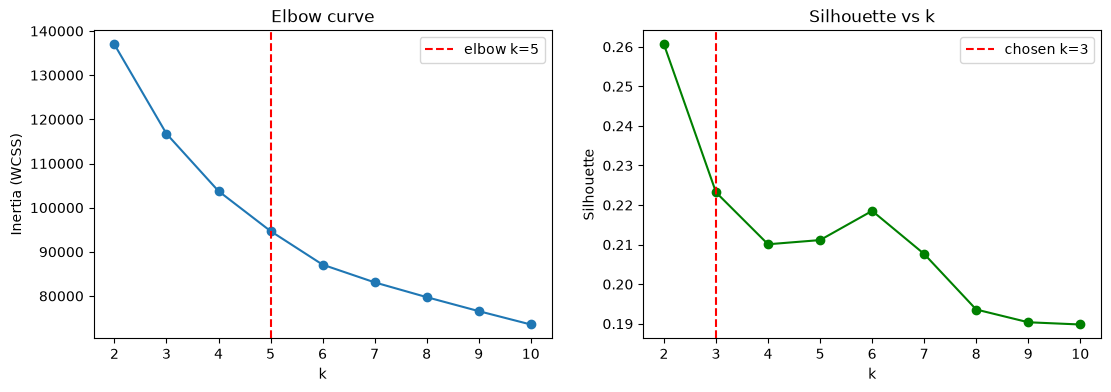

In [72]:

ks = list(range(2, 11))
inertia = []
sil = []

for k in ks:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42).fit(Xs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xs, km.labels_))
    
k_elbow = ks[knee_index(inertia)]
cand = {k: s for k, s in zip(ks, sil) if 3 <= k <= 8}
k_optimal = max(cand, key=cand.get)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ks, inertia, 'o-')
ax[0].axvline(k_elbow, color='r', ls='--', label=f'elbow k={k_elbow}')
ax[0].set(xlabel='k', ylabel='Inertia (WCSS)', title='Elbow curve')
ax[0].legend()
ax[1].plot(ks, sil, 'o-g')
ax[1].axvline(k_optimal, color='r', ls='--', label=f'chosen k={k_optimal}')
ax[1].set(xlabel='k', ylabel='Silhouette', title='Silhouette vs k')
ax[1].legend()
plt.savefig("../images/03.kmeans_cluster_selection.png")
plt.show()

- The elbow curve shows how within-cluster inertia decreases as the number of clusters increases. The silhouette curve measures how well-separated the clusters are. Together, these plots help select a cluster count that balances compact groups with clear separation.


In [33]:
display(pd.DataFrame({'k': ks, 'inertia': np.round(inertia, 0), 'silhouette': np.round(sil, 4)}).set_index('k').T)
print(f"Highest silhouette overall: k={ks[int(np.argmax(sil))]} ({max(sil):.3f}); highest for k in 3-8: k={k_optimal} ({cand[k_optimal]:.3f}); elbow at k={k_elbow}.")
print(f"Choice: k={k_optimal}.")

k,2,3,4,5,6,7,8,9,10
inertia,136948.0000,116739.0000,103751.0000,94696.0000,87096.0000,83083.0000,79738.0000,76570.0000,73543.0000
silhouette,0.2606,0.2232,0.2101,0.2111,0.2185,0.2076,0.1936,0.1904,0.1898


Highest silhouette overall: k=2 (0.261); highest for k in 3-8: k=3 (0.223); elbow at k=5.
Choice: k=3.


- It maximises the silhouette among useful segment counts (3-8) and sits near the elbow where extra clusters give diminishing inertia reduction; k=2 only splits customers into two broad groups, too coarse for product targeting.

### 3.2 Final K-Means model

In [34]:
kmeans = KMeans(n_clusters=k_optimal, init='k-means++', n_init=20, max_iter=500, random_state=42).fit(Xs)
km_labels = kmeans.labels_
feats = fe_cap.copy()
feats['KMeans_Cluster'] = km_labels
print(feats['KMeans_Cluster'].value_counts().sort_index().to_dict())

{0: 3207, 1: 2867, 2: 2876}


### 3.3 Visualise

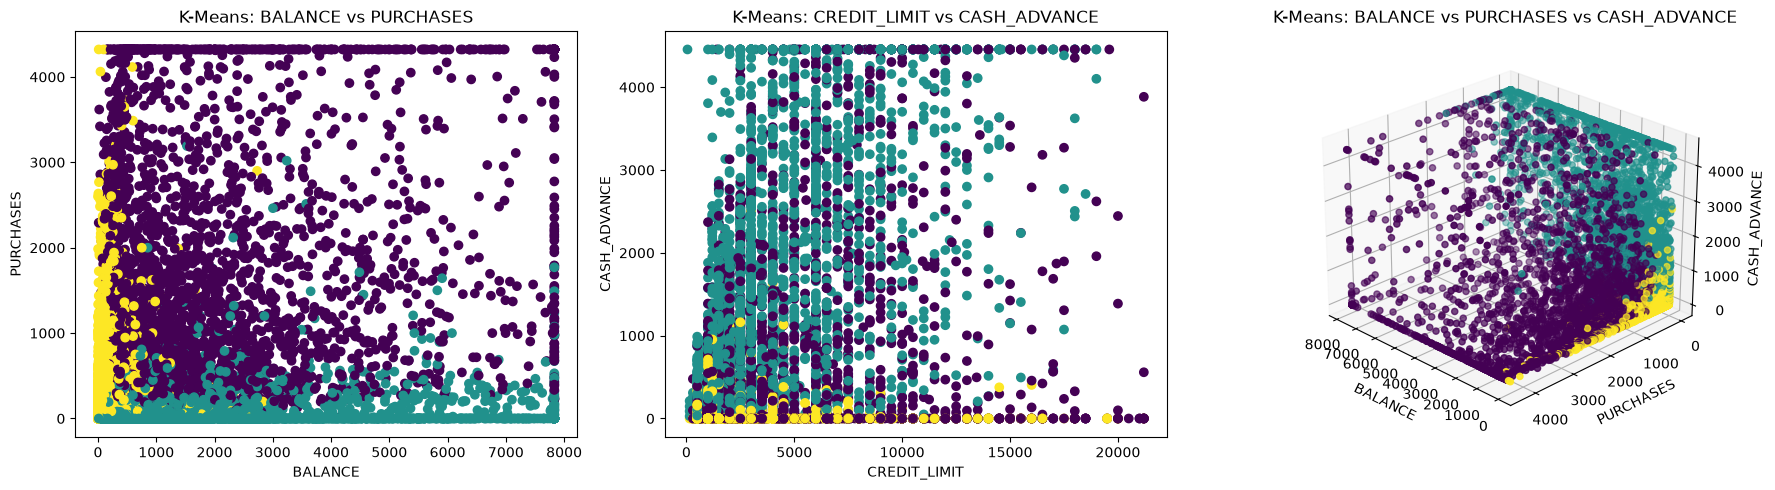

In [73]:

fig = plt.figure(figsize=(18, 5))

ax = [
    fig.add_subplot(1, 3, 1),
    fig.add_subplot(1, 3, 2),
    fig.add_subplot(1, 3, 3, projection='3d')
]

ax[0].scatter(feats['BALANCE'], feats['PURCHASES'], c=km_labels, cmap='viridis')
ax[0].set(xlabel='BALANCE', ylabel='PURCHASES', title='K-Means: BALANCE vs PURCHASES')

ax[1].scatter(feats['CREDIT_LIMIT'], feats['CASH_ADVANCE'], c=km_labels, cmap='viridis')
ax[1].set(xlabel='CREDIT_LIMIT', ylabel='CASH_ADVANCE', title='K-Means: CREDIT_LIMIT vs CASH_ADVANCE')

ax[2].scatter(feats['BALANCE'], feats['PURCHASES'], feats['CASH_ADVANCE'], c=km_labels, cmap='viridis')
ax[2].set(xlabel='BALANCE', ylabel='PURCHASES', zlabel='CASH_ADVANCE', title='K-Means: BALANCE vs PURCHASES vs CASH_ADVANCE')
ax[2].view_init(25, 135)

plt.tight_layout()
plt.savefig("../images/04.kmeans_balance_vs_purchases_&_3d_clusters.png")
plt.show()

- Each point represents a customer, colored by their K-Means cluster. The plot shows how the groups differ in balance and purchase activity. Clusters that overlap in this two-feature view may still differ on other features used by the model.

- This plot displays the K-Means clusters using balance, purchases, and cash advance. The third feature may reveal group differences that are less visible in the 2D plot. The viewing angle can affect how clearly the groups appear.


### 3.4 Profile

In [39]:
km_prof = profile(fe_cap, km_labels)
km_pers = name_clusters(km_prof)
show_profile(km_prof, km_pers)

,Persona,Size,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,TENURE,PRC_FULL_PAYMENT,PURCHASES_FREQUENCY
C,,,,,,,,,,
0,Premium Spenders,"3,207","2,025.23","1,820.39",665.79,"5,566.76","2,221.23",11.75,0.14,0.82
1,Cash-Advance Reliant,"2,867","2,290.21",83.81,"1,752.43","4,231.54","1,476.26",11.35,0.03,0.07
2,Low-Balance Full Payers,"2,876",182.13,496.95,22.55,"3,548.29",700.93,11.42,0.29,0.54


Cluster 0 -> Premium Spenders: balance 1.3x, purchases 2.2x, cash advance 0.8x, credit limit 1.2x, full-payment share 0.9x the portfolio average
Cluster 1 -> Cash-Advance Reliant: balance 1.5x, purchases 0.1x, cash advance 2.2x, credit limit 0.9x, full-payment share 0.2x the portfolio average
Cluster 2 -> Low-Balance Full Payers: balance 0.1x, purchases 0.6x, cash advance 0.0x, credit limit 0.8x, full-payment share 1.9x the portfolio average


## Step 4 - Agglomerative Hierarchical Clustering
### 4.1 Dendrogram

Cut heights giving 3 / 4 / 5 clusters: {3: np.float64(168.4), 4: np.float64(136.0), 5: np.float64(117.5)}


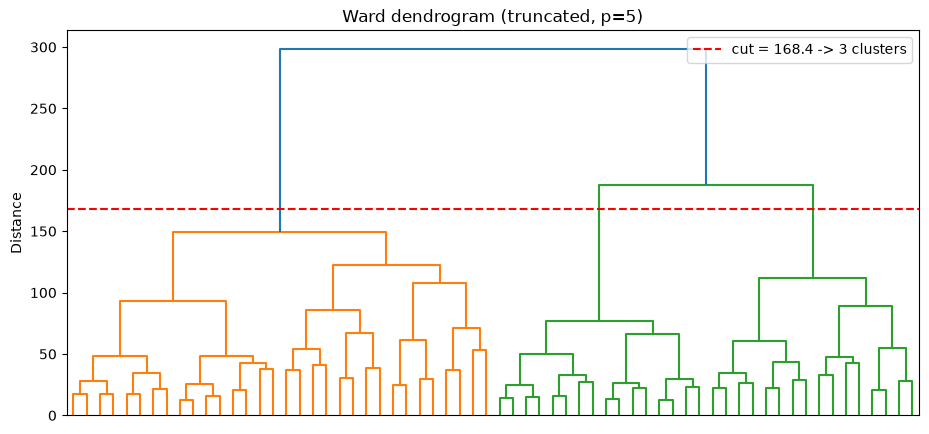

Chosen cut: distance 168.4 -> 3 clusters (matched to the K-Means k, bounded to 3-5, for comparability).


In [74]:

Z = linkage(Xs, method='ward')
n_chosen = min(max(k_optimal, 3), 5)
cuts = {n: (Z[-n, 2] + Z[-(n - 1), 2]) / 2 for n in (3, 4, 5)}
print('Cut heights giving 3 / 4 / 5 clusters:', {n: round(h, 1) for n, h in cuts.items()})
plt.figure(figsize=(11, 5))
dendrogram(Z, truncate_mode='level', p=5, no_labels=True)
plt.axhline(cuts[n_chosen], color='r', ls='--', label=f'cut = {cuts[n_chosen]:.1f} -> {n_chosen} clusters')
plt.legend()
plt.title('Ward dendrogram (truncated, p=5)')
plt.ylabel('Distance')
plt.savefig("../images/05.hierarchical_dendrogram.png")
plt.show()
print(f'Chosen cut: distance {cuts[n_chosen]:.1f} -> {n_chosen} clusters (matched to the K-Means k, bounded to 3-5, for comparability).')

- The dendrogram shows how individual customers or groups are progressively merged. Larger vertical distances between merges suggest greater separation between groups. The selected cut level determines the final number of clusters.


### 4.2 Train & compare linkages

In [41]:
agg_sil, agg_lab = {}, {}
for lk in ['ward', 'complete', 'average']:
    agg_lab[lk] = AgglomerativeClustering(n_clusters=n_chosen, linkage=lk).fit_predict(Xs)
    agg_sil[lk] = silhouette_score(Xs, agg_lab[lk])
    print(f"{lk:9s} silhouette={agg_sil[lk]:.4f} sizes={np.bincount(agg_lab[lk]).tolist()}")
    
elig = {l: v for l, v in agg_sil.items() if np.bincount(agg_lab[l]).min() >= .02 * len(Xs)} or agg_sil 
best_link = max(elig, key=elig.get)
agg_labels = agg_lab[best_link]
feats['Agg_Cluster'] = agg_labels
print('Best linkage (silhouette, among linkages whose smallest cluster is >= 2% of customers):', best_link)

ward      silhouette=0.1981 sizes=[4767, 2385, 1798]
complete  silhouette=0.1674 sizes=[2587, 1663, 4700]
average   silhouette=0.2125 sizes=[8944, 4, 2]
Best linkage (silhouette, among linkages whose smallest cluster is >= 2% of customers): ward


### 4.3 Visualise, profile, compare with K-Means

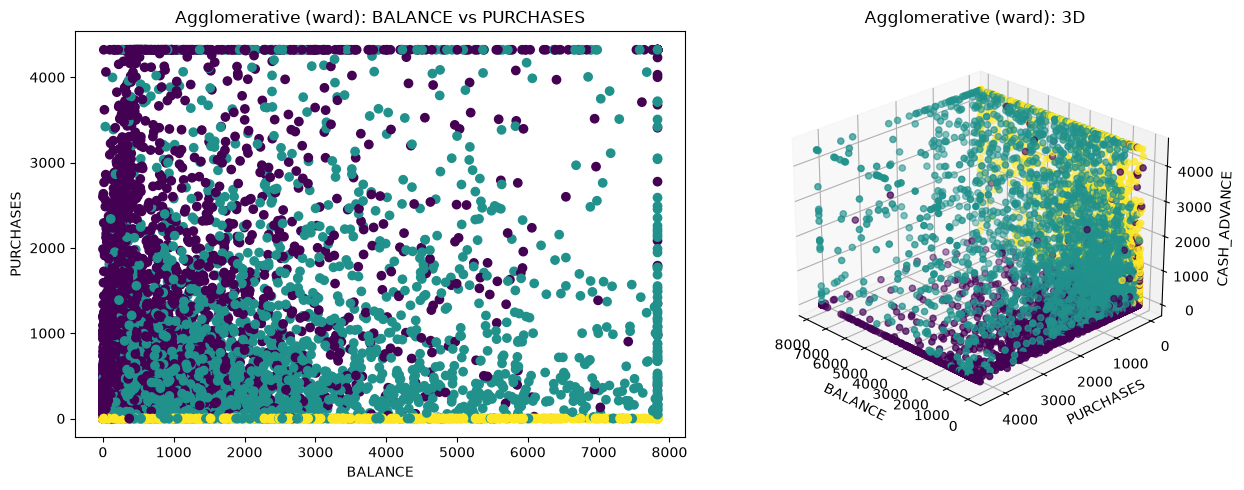

In [76]:

fig = plt.figure(figsize=(13, 5))

ax = [
    fig.add_subplot(1, 2, 1),
    fig.add_subplot(1, 2, 2, projection='3d')
]

ax[0].scatter(feats['BALANCE'], feats['PURCHASES'], c=agg_labels, cmap='viridis')
ax[0].set(xlabel='BALANCE', ylabel='PURCHASES', title=f'Agglomerative ({best_link}): BALANCE vs PURCHASES')

ax[1].scatter(feats['BALANCE'], feats['PURCHASES'], feats['CASH_ADVANCE'], c=agg_labels, cmap='viridis')
ax[1].set(xlabel='BALANCE', ylabel='PURCHASES', zlabel='CASH_ADVANCE', title=f'Agglomerative ({best_link}): 3D')
ax[1].view_init(25, 135)

plt.tight_layout()
plt.savefig("../images/06.hierarchical_balance_vs_purchases_&_3d_clusters.png")
plt.show()

- The colors show the customer groups produced by hierarchical clustering. Compare this plot with the K-Means version to see where the methods assign customers similarly and where their cluster boundaries differ.
- This plot shows the hierarchical clusters across balance, purchases, and cash advance. It provides a three-feature view of the segments and can reveal differences that may not be visible in the 2D plot.


In [45]:
agg_prof = profile(fe_cap, agg_labels)
agg_pers = name_clusters(agg_prof)
show_profile(agg_prof, agg_pers)

,Persona,Size,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,TENURE,PRC_FULL_PAYMENT,PURCHASES_FREQUENCY
C,,,,,,,,,,
1,Cash-Advance Reliant 1,"2,385","2,515.18",981.59,"1,771.36","5,026.93","1,975.58",11.16,0.06,0.54
0,Transactors,"4,767",780.40,"1,083.54",33.67,"4,377.17","1,240.04",11.61,0.24,0.65
2,Cash-Advance Reliant 2,"1,798","2,150.11",0.64,"1,579.00","4,079.04","1,528.79",11.74,0.05,0.00


Cluster 1 -> Cash-Advance Reliant 1: balance 1.7x, purchases 1.2x, cash advance 2.2x, credit limit 1.1x, full-payment share 0.4x the portfolio average
Cluster 0 -> Transactors: balance 0.5x, purchases 1.3x, cash advance 0.0x, credit limit 1.0x, full-payment share 1.6x the portfolio average
Cluster 2 -> Cash-Advance Reliant 2: balance 1.4x, purchases 0.0x, cash advance 2.0x, credit limit 0.9x, full-payment share 0.3x the portfolio average


In [46]:
ari = adjusted_rand_score(km_labels, agg_labels)
display(pd.crosstab(pd.Series(km_labels, name='KMeans'), pd.Series(agg_labels, name='Agglomerative')))

Agglomerative,0,1,2
KMeans,,,
0,1883,1324,0
1,146,983,1738
2,2738,78,60


In [48]:
agreement_summary = (
    "The two methods broadly agree."
    if ari >= 0.6
    else f"They only partly agree. The '{best_link}' linkage draws boundaries differently, "
         "so some K-Means clusters are split or merged."
)

display(Markdown(
    f"**Adjusted Rand Index (K-Means vs. Hierarchical):** {ari:.2f}\n\n"
    f"{agreement_summary}\n\n"
    "Ward and K-Means-like linkages tend to produce compact, balanced clusters. "
    "Complete linkage produces more unequal cluster sizes, while average linkage "
    "falls between them."
))

**Adjusted Rand Index (K-Means vs. Hierarchical):** 0.33

They only partly agree. The 'ward' linkage draws boundaries differently, so some K-Means clusters are split or merged.

Ward and K-Means-like linkages tend to produce compact, balanced clusters. Complete linkage produces more unequal cluster sizes, while average linkage falls between them.

## Step 5 - DBSCAN
### 5.1 Tune ε with the k-NN distance plot (MinPts = 5)

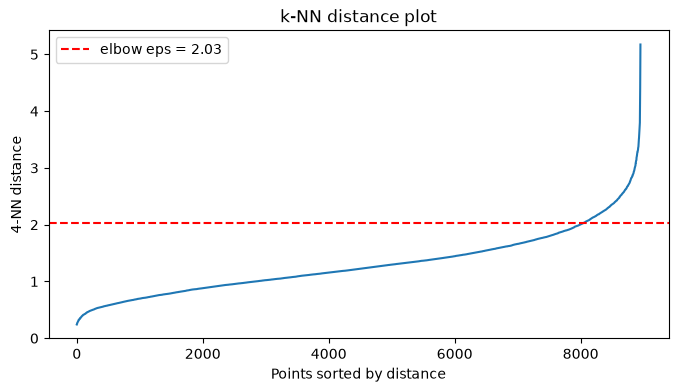

In [77]:

nn = NearestNeighbors(n_neighbors=5).fit(Xs)
d, _ = nn.kneighbors(Xs)
kd = np.sort(d[:, -1])
ki = knee_index(kd)
optimal_eps = float(kd[ki])
plt.figure(figsize=(8, 4))
plt.plot(kd)
plt.axhline(optimal_eps, color='r', ls='--', label=f'elbow eps = {optimal_eps:.2f}')
plt.xlabel('Points sorted by distance')
plt.ylabel('4-NN distance')
plt.title('k-NN distance plot')
plt.legend()
plt.savefig("../images/07.dbscan_k_distance.png")
plt.show()

- The k-distance plot sorts each customer’s distance to a nearby neighbor. The bend, or “knee,” provides a guide for selecting DBSCAN’s epsilon value. This choice is approximate and can affect the number of clusters and noise points.


### 5.2 Train DBSCAN

In [51]:
db = DBSCAN(eps=optimal_eps, min_samples=5, metric='euclidean').fit(Xs)
dl = db.labels_
print(f'clusters (excl. noise): {len(set(dl) - {-1})} | noise points: {(dl == -1).sum()} | noise %: {(dl == -1).mean() * 100:.2f}%')

clusters (excl. noise): 9 | noise points: 505 | noise %: 5.64%


### 5.3 Tune hyper-parameters (grid)

In [53]:
def internal_metrics(X, labels):
    m = labels != -1
    if len(set(labels[m])) < 2: return np.nan, np.nan, np.nan
    return (silhouette_score(X[m], labels[m]), davies_bouldin_score(X[m], labels[m]), calinski_harabasz_score(X[m], labels[m]))

rows = []
for e in [0.3, 0.5, 0.7, 1.0, 1.5, round(optimal_eps, 2)]:
    for ms in [3, 5, 8, 10]:
        l = DBSCAN(eps=e, min_samples=ms).fit_predict(Xs)
        s = internal_metrics(Xs, l)[0]
        rows.append({'eps': e, 'min_samples': ms, 'n_clusters': len(set(l) - {-1}), 'noise_pct': (l == -1).mean() * 100, 'silhouette': s})

grid = pd.DataFrame(rows)
grid.round(3).head()

,eps,min_samples,n_clusters,noise_pct,silhouette
0,0.3,3,24,98.581,0.542
1,0.3,5,5,99.475,0.412
2,0.3,8,0,100.000,NaN
3,0.3,10,0,100.000,NaN
4,0.5,3,90,91.106,0.187


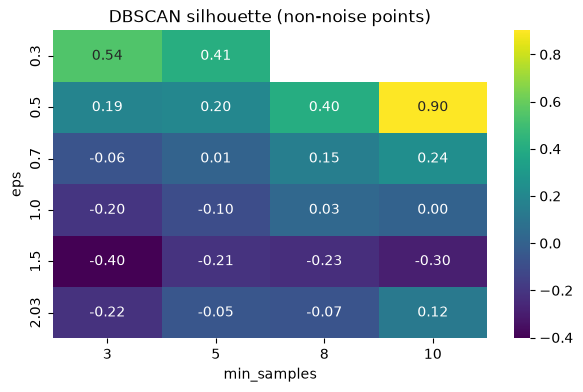

In [54]:
plt.figure(figsize=(7, 4))
sns.heatmap(grid.pivot(index='eps', columns='min_samples', values='silhouette'), annot=True, fmt='.2f', cmap='viridis')
plt.title('DBSCAN silhouette (non-noise points)')
plt.show()

In [55]:
ok = grid[(grid.n_clusters.between(2, 10)) & (grid.noise_pct <= 20) & (grid.silhouette > 0)]
best_row = (ok if len(ok) else grid.dropna(subset=['silhouette'])).sort_values('silhouette', ascending=False).iloc[0]
best_eps, best_ms = float(best_row.eps), int(best_row.min_samples)
print(f"Best combination (2-10 clusters, <=20% noise, max silhouette; the k-NN eps is included in the grid): eps={best_eps}, min_samples={best_ms}")
db = DBSCAN(eps=best_eps, min_samples=best_ms).fit(Xs)
dl = db.labels_
feats['DBSCAN_Cluster'] = dl
print('Retrained: clusters =', len(set(dl) - {-1}), '| noise % =', round((dl == -1).mean() * 100, 2))

Best combination (2-10 clusters, <=20% noise, max silhouette; the k-NN eps is included in the grid): eps=2.03, min_samples=10
Retrained: clusters = 3 | noise % = 8.29


### 5.4 Visualise & profile

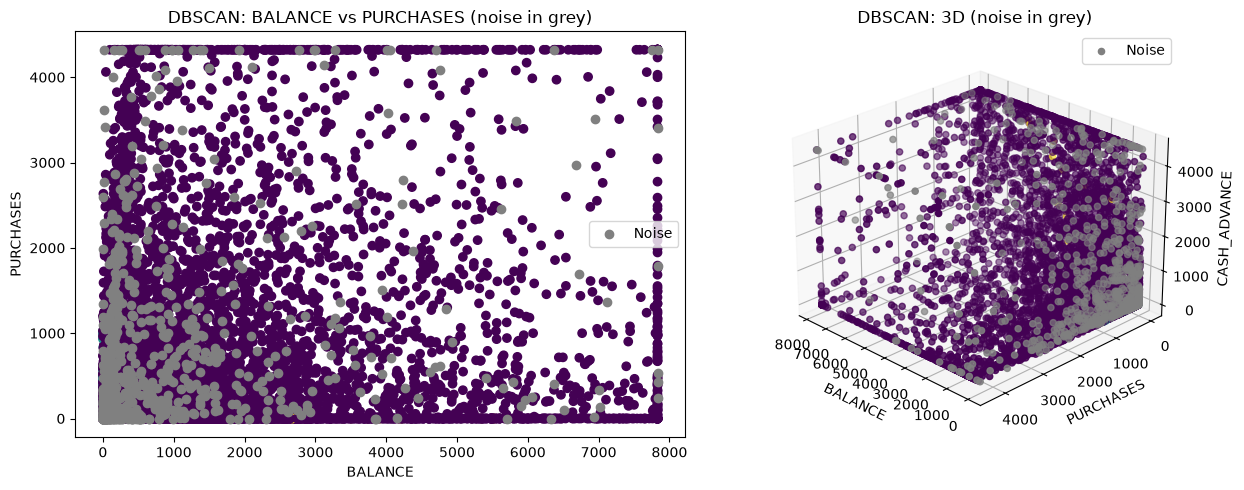

In [ ]:

fig = plt.figure(figsize=(13, 5))

ax = [
    fig.add_subplot(1, 2, 1),
    fig.add_subplot(1, 2, 2, projection='3d')
]

labels = np.asarray(dl)
noise = labels == -1
clusters = ~noise

ax[0].scatter(feats.loc[clusters, 'BALANCE'], feats.loc[clusters, 'PURCHASES'], c=labels[clusters], cmap='viridis')
ax[0].scatter(feats.loc[noise, 'BALANCE'], feats.loc[noise, 'PURCHASES'], color='grey', label='Noise')
ax[0].set(xlabel='BALANCE', ylabel='PURCHASES', title='DBSCAN: BALANCE vs PURCHASES (noise in grey)')
ax[0].legend()

ax[1].scatter(feats.loc[clusters, 'BALANCE'], feats.loc[clusters, 'PURCHASES'], feats.loc[clusters, 'CASH_ADVANCE'], c=labels[clusters], cmap='viridis')
ax[1].scatter(feats.loc[noise, 'BALANCE'], feats.loc[noise, 'PURCHASES'], feats.loc[noise, 'CASH_ADVANCE'], color='grey', label='Noise')
ax[1].set(xlabel='BALANCE', ylabel='PURCHASES', zlabel='CASH_ADVANCE', title='DBSCAN: 3D (noise in grey)')
ax[1].legend()
ax[1].view_init(25, 135)

plt.tight_layout()
plt.savefig("../images/08.dbscan_balance_vs_purchases_&_3d_clusters.png")
plt.show()

- The plot shows the dense customer groups identified by DBSCAN. Grey points are observations classified as noise under the selected settings. These points are isolated according to the algorithm and are not necessarily errors.
- This plot displays DBSCAN’s groups using balance, purchases, and cash advance. Grey points represent noise. The additional feature can help show how the identified clusters relate in three dimensions.


In [62]:
db_prof = profile(fe_cap, dl); db_pers = name_clusters(db_prof) if len(db_prof) else {}
if len(db_prof): show_profile(db_prof, db_pers)
nz = fe_cap[dl == -1]

if len(nz):
    r = (nz[['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT']].mean() / fe_cap[['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT']].mean()).round(2)
    print(f"Noise customers ({len(nz)}) average vs portfolio: {r.to_dict()} (x overall mean).")
    print("These are unusual accounts (extreme spend, cash-advance or limit behaviour) that fit no dense segment. For credit-risk they warrant manual review; "
          "for marketing they are candidates for bespoke relationship-manager offers rather than mass campaigns.")

,Persona,Size,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,TENURE,PRC_FULL_PAYMENT,PURCHASES_FREQUENCY
C,,,,,,,,,,
0,Moderate Users,"8,129","1,577.90",844.45,781.50,"4,519.64","1,498.95",11.68,0.15,0.49
2,Cash-Advance Reliant,12,"3,348.67",0.00,"2,499.53","4,225.00",0.00,12.00,0.00,0.00
1,Dormant Cardholders,67,8.70,225.95,1.52,"4,095.52",0.00,11.79,0.00,0.33


Cluster 0 -> Moderate Users: balance 1.0x, purchases 1.0x, cash advance 1.0x, credit limit 1.0x, full-payment share 1.0x the portfolio average
Cluster 2 -> Cash-Advance Reliant: balance 2.2x, purchases 0.0x, cash advance 3.1x, credit limit 0.9x, full-payment share 0.0x the portfolio average
Cluster 1 -> Dormant Cardholders: balance 0.0x, purchases 0.3x, cash advance 0.0x, credit limit 0.9x, full-payment share 0.0x the portfolio average
Noise customers (742) average vs portfolio: {'BALANCE': 0.64, 'PURCHASES': 1.01, 'CASH_ADVANCE': 1.4, 'CREDIT_LIMIT': 0.94} (x overall mean).
These are unusual accounts (extreme spend, cash-advance or limit behaviour) that fit no dense segment. For credit-risk they warrant manual review; for marketing they are candidates for bespoke relationship-manager offers rather than mass campaigns.


## Step 6 - Algorithm Comparison & Business Interpretation
### 6.1 Internal metrics

In [63]:
res = []
for name, lab, par in [('K-Means', km_labels, f'k={k_optimal}, init=k-means++, n_init=20'),
                       ('Agglomerative', agg_labels, f'n_clusters={n_chosen}, linkage={best_link}'),
                       ('DBSCAN', dl, f'eps={best_eps}, min_samples={best_ms}')]:
    s, b, c = internal_metrics(Xs, lab)
    res.append({'Algorithm': name, 'Hyperparameters': par, 'Clusters': len(set(lab) - {-1}), 'Silhouette (↑)': s, 'Davies-Bouldin (↓)': b, 'Calinski-Harabasz (↑)': c, 'Noise %': (lab == -1).mean() * 100})
    
cmp_df = pd.DataFrame(res).set_index('Algorithm')
cmp_df['Avg rank'] = (cmp_df['Silhouette (↑)'].rank(ascending=False, na_option='bottom') + cmp_df['Davies-Bouldin (↓)'].rank(na_option='bottom') + cmp_df['Calinski-Harabasz (↑)'].rank(ascending=False, na_option='bottom')) / 3
display(cmp_df.style.format({'Silhouette (↑)': '{:.3f}', 'Davies-Bouldin (↓)': '{:.3f}', 'Calinski-Harabasz (↑)': '{:,.0f}', 'Noise %': '{:.2f}', 'Avg rank': '{:.2f}'}))

metric_best = cmp_df['Avg rank'].idxmin()
usable = cmp_df[(cmp_df.Clusters >= 3) & (cmp_df['Noise %'] <= 5)]
recommended = usable['Avg rank'].idxmin() if len(usable) else metric_best
print('Ranking by metrics:', cmp_df['Avg rank'].sort_values().index.tolist())
print(f'Best by metrics: {metric_best} | Recommended for deployment (>=3 segments, <=5% noise): {recommended}')

,Hyperparameters,Clusters,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),Noise %,Avg rank
Algorithm,,,,,,,
K-Means,"k=3, init=k-means++, n_init=20",3,0.223,1.679,"2,729",0.00,1.33
Agglomerative,"n_clusters=3, linkage=ward",3,0.198,1.728,"2,213",0.00,2.33
DBSCAN,"eps=2.03, min_samples=10",3,0.122,0.951,87,8.29,2.33


Ranking by metrics: ['K-Means', 'Agglomerative', 'DBSCAN']
Best by metrics: K-Means | Recommended for deployment (>=3 segments, <=5% noise): K-Means


### 6.2 K-Means stability

In [64]:
st = []
for rs in [0, 7, 21, 42, 99]:
    st.append(silhouette_score(Xs, KMeans(n_clusters=k_optimal, init='k-means++', n_init=10, random_state=rs).fit_predict(Xs)))
    
print('Silhouette per seed:', np.round(st, 4)); print(f'Mean ± std = {np.mean(st):.4f} ± {np.std(st):.4f}')
print('K-Means is ' + ('stable: scores barely change across seeds.' if np.std(st) < .01 else 'somewhat sensitive to the seed.'))

Silhouette per seed: [0.2232 0.2232 0.2232 0.2232 0.2232]
Mean ± std = 0.2232 ± 0.0000
K-Means is stable: scores barely change across seeds.


### 6.3 Business recommendation

In [65]:
LAB = {'K-Means': km_labels, 'Agglomerative': agg_labels, 'DBSCAN': dl}
REC_LABELS = LAB[recommended]
rec_prof = profile(fe_cap, REC_LABELS)
rec_pers = name_clusters(rec_prof)
seg = '\n'.join(f"- **{rec_pers[k]['name']}** ({int(rec_prof.loc[k, 'Size'])} customers, {rec_prof.loc[k, 'Size'] / len(df) * 100:.0f}%): {rec_pers[k]['why']}. **Action:** {rec_pers[k]['action']}" for k in rec_prof.index)

display(Markdown(f"""### Recommendation to the Head of Cards & Payments
**Algorithm:** deploy **{recommended}**. By internal metrics {metric_best} ranks first; {recommended} is recommended because it assigns every cardholder to one of {rec_prof.shape[0]} actionable segments, scores silhouette {cmp_df.loc[recommended, 'Silhouette (↑)']:.2f}, and is stable across random seeds (std {np.std(st):.3f}). DBSCAN is useful as a companion tool to flag {(dl == -1).mean() * 100:.1f}% unusual accounts for manual review.

**Segments identified ({rec_prof.shape[0]}):**
{seg}

**Additional data that would improve the next iteration:** transaction-level merchant categories, month-by-month trends (not only averages), delinquency/default history, income and demographics, channel/app engagement, and attrition labels to validate segments against actual churn."""))

### Recommendation to the Head of Cards & Payments
**Algorithm:** deploy **K-Means**. By internal metrics K-Means ranks first; K-Means is recommended because it assigns every cardholder to one of 3 actionable segments, scores silhouette 0.22, and is stable across random seeds (std 0.000). DBSCAN is useful as a companion tool to flag 8.3% unusual accounts for manual review.

**Segments identified (3):**
- **Premium Spenders** (3207 customers, 36%): balance 1.3x, purchases 2.2x, cash advance 0.8x, credit limit 1.2x, full-payment share 0.9x the portfolio average. **Action:** Upgrade to a premium/super-premium card with travel and lifestyle rewards and a higher limit.
- **Cash-Advance Reliant** (2867 customers, 32%): balance 1.5x, purchases 0.1x, cash advance 2.2x, credit limit 0.9x, full-payment share 0.2x the portfolio average. **Action:** Offer a low-rate personal loan or cash-advance-to-EMI conversion; monitor credit risk.
- **Low-Balance Full Payers** (2876 customers, 32%): balance 0.1x, purchases 0.6x, cash advance 0.0x, credit limit 0.8x, full-payment share 1.9x the portfolio average. **Action:** Drive spend with cashback/EMI-on-card offers and merchant tie-ups; they are low-risk and under-used.

**Additional data that would improve the next iteration:** transaction-level merchant categories, month-by-month trends (not only averages), delinquency/default history, income and demographics, channel/app engagement, and attrition labels to validate segments against actual churn.

## Step 7 - Pipeline & Deployment
### 7.1 Save scaler + model, **predict_segment()**

In [68]:
if recommended == 'K-Means': 
    deploy_model = kmeans
else:
    m = REC_LABELS != -1; deploy_model = KNeighborsClassifier(n_neighbors=15).fit(Xs[m], REC_LABELS[m])
    
bundle = {'model': deploy_model, 'algorithm': recommended, 'caps': caps, 'log_cols': LOG_COLS, 'feature_columns': FEAT_COLS, 'raw_columns': RAW_COLS,
          'defaults': df.median().to_dict(), 'personas': {int(k): v for k, v in rec_pers.items()}, 'profile': rec_prof}
joblib.dump(scaler, '../models/cc_scaler.pkl'); joblib.dump(bundle, '../models/cc_segmentation_model.pkl') 

def preprocess(raw_df, b):
    f = add_features(raw_df)
    for c, u in b['caps'].items(): f[c] = f[c].clip(upper=u)
    f[b['log_cols']] = np.log1p(f[b['log_cols']])
    return f[b['feature_columns']]

def predict_segment(raw):
    sc, b = joblib.load('cc_scaler.pkl'), joblib.load('cc_segmentation_model.pkl')
    row = pd.DataFrame([{**b['defaults'], **raw}])
    c = int(b['model'].predict(sc.transform(preprocess(row, b)))[0]); p = b['personas'][c]
    return c, p['name'], p['action']

assert np.allclose(scaler.transform(preprocess(df, bundle)), Xs), 'pipeline mismatch'
print('Pipeline check passed. Saved: cc_scaler.pkl, cc_segmentation_model.pkl')

Pipeline check passed. Saved: cc_scaler.pkl, cc_segmentation_model.pkl


### 7.3 Summary report (`summary_report.md`)

In [67]:
n_never = (df.PURCHASES == 0).mean() * 100
segs = '\n'.join(f"- **{rec_pers[k]['name']}** ({rec_prof.loc[k, 'Size'] / len(df) * 100:.0f}%): {rec_pers[k]['why']}." for k in rec_prof.index)
rep = f"""# Credit Card Customer Segmentation — Summary Report

## 1. Business problem and dataset
A large Indian private bank wants to replace one-size-fits-all card offers with behavioural segments so Relationship Managers can give the right product to the right customer, reducing attrition and raising wallet share. The data is the Kaggle credit-card clustering dataset: {len(df) + 0:,} active cardholders and 17 behavioural and financial columns (balance, purchases, cash advance, credit limit, payments, tenure and frequencies). `CUST_ID` was dropped; {imputed['CREDIT_LIMIT']} missing CREDIT_LIMIT and {imputed['MINIMUM_PAYMENTS']:,} missing MINIMUM_PAYMENTS values were imputed with the median. {n_never:.1f}% of customers never made a purchase, and the top {pareto / len(df) * 100:.0f}% of customers generate 80% of purchase volume.

## 2. Feature engineering and preprocessing
Four behavioural features were added: Monthly_Avg_Purchase, Monthly_Avg_Cash_Advance, Limit_Usage (balance / limit) and Payment_to_Minpayment_Ratio. Money columns are heavily right-skewed with extreme values, so outliers were winsorised at Q3 + 3×IQR (no rows dropped) and log1p-transformed, then standardised, because K-Means, hierarchical clustering and DBSCAN are all distance-based and scale-sensitive.

## 3. Algorithm comparison
| Algorithm | Settings | Clusters | Silhouette | Davies-Bouldin | Calinski-Harabasz | Noise % |
|---|---|---|---|---|---|---|
""" + '\n'.join(f"| {n} | {r['Hyperparameters']} | {r['Clusters']} | {r['Silhouette (↑)']:.3f} | {r['Davies-Bouldin (↓)']:.3f} | {r['Calinski-Harabasz (↑)']:,.0f} | {r['Noise %']:.1f} |" for n, r in cmp_df.iterrows()) + f"""

{metric_best} ranks first on the combined metric ranking; **{recommended}** is the recommended model for deployment because it covers all customers with {rec_prof.shape[0]} actionable segments and is stable across seeds (silhouette std {np.std(st):.3f}). Hierarchical and K-Means agreement (ARI) is {ari:.2f}. DBSCAN flags {(dl == -1).mean() * 100:.1f}% of customers as noise — unusual accounts best handled by manual review.

## 4. Segments
{segs}

## 5. Business actions
""" + '\n'.join(f"- {rec_pers[k]['name']}: {rec_pers[k]['action']}" for k in rec_prof.index) + """

## 6. Next steps
Add transaction-level and time-series features (spend trends, merchant categories), delinquency and churn labels for semi-supervised refinement, and serve the saved scaler and model behind a real-time scoring API (a Streamlit prototype, `app.py`, is included).
"""
open('../report/summary_report.md', 'w', encoding='utf-8').write(rep)
print('summary_report.md written; words:', len(rep.split()))

summary_report.md written; words: 438
